# VAE-based minority-class image generation

Archived companion notebook for the master's thesis on SEM defect classification with conformal prediction. This publication copy changes documentation only; executable statements and historical outputs are preserved.

## Reading this notebook

You do not need to execute any cells to inspect the saved outputs. Training and generation cells write to the original Google Drive workspace and may overwrite files. No new execution or training has been performed for this edition.

## Experimental scope

The VAE uses all 55 original Class 1 images and generates 50 synthetic images. The downstream CNN experiments use the first 6, 17, or 28 saved images. Because the VAE also sees images later held out from CNN training, downstream results must be interpreted with this data-separation limitation.


## 1. Setup and plotting defaults

Import dependencies and mount Google Drive. Paths below refer to the original thesis workspace.


In [ ]:
# --- Step 1: Setup and Libraries ---
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import os
import shutil
import pathlib
from google.colab import drive

drive.mount('/content/drive')

# --- Global Plot Style ---
mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': ':',
    'grid.alpha': 0.5,
    'lines.linewidth': 1.8,
    'figure.dpi': 150,
})
COLORS = ['#2c7bb6', '#d7191c', '#1a9641', '#fdae61']

print("TensorFlow Version:", tf.__version__)
print("Setup complete.")


Mounted at /content/drive
TensorFlow Version: 2.19.0
Setup complete.


## 2. Load original Class 1 images

This archived experiment loads all 55 Class 1 images, without a held-out split for the VAE. Some of these images are later used for CNN calibration and testing, creating an indirect data leakage pathway.


In [ ]:
# Load all original Class 1 images used in the archived experiment.
dataset_path = pathlib.Path('/content/drive/MyDrive/CarinthiaDataset')
images_path  = dataset_path / 'classified_images' / 'class_1'
figures_path = dataset_path / 'figures'
models_path  = dataset_path / 'models'
os.makedirs(figures_path, exist_ok=True)
os.makedirs(models_path,  exist_ok=True)

# Copy locally for faster I/O
local_dir = pathlib.Path('/content/class_1_data')
if local_dir.exists(): shutil.rmtree(local_dir)
shutil.copytree(images_path, local_dir)

image_paths = sorted(local_dir.glob('*.jpg'))
print(f"Class 1 images found: {len(image_paths)}")

IMG_SIZE   = (224, 224)
BATCH_SIZE = 8   # small – only 55 images

def load_and_preprocess(path):
    img = tf.io.read_file(str(path))
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img

images_list = [load_and_preprocess(p) for p in image_paths]
images_np   = np.stack(images_list, axis=0)
dataset     = tf.data.Dataset.from_tensor_slices(images_np)\
                .shuffle(len(images_np))\
                .batch(BATCH_SIZE)\
                .prefetch(tf.data.AUTOTUNE)

print(f"Dataset ready. Image shape: {images_np.shape}")


Class 1 images found: 55
Dataset ready. Image shape: (55, 224, 224, 3)


## 3. Define the variational autoencoder

The encoder predicts a diagonal Gaussian latent distribution. The decoder reconstructs RGB images. Training minimizes reconstruction loss plus KL divergence.


In [ ]:
# --- Step 3: VAE Architecture ---
latent_dim = 128

class Sampling(layers.Layer):
    """Reparameterization trick: z = mu + eps * sigma"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch   = tf.shape(z_mean)[0]
        dim     = tf.shape(z_mean)[1]
        epsilon = tf.keras.backend.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# Encoder
encoder_inputs = keras.Input(shape=(224, 224, 3))
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(16, activation="relu")(x)
z_mean    = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z         = Sampling()([z_mean, z_log_var])
encoder   = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")

# Decoder
latent_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(56 * 56 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((56, 56, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = layers.Conv2DTranspose(3, 3, activation="sigmoid", padding="same")(x)
decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker         = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker= keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker            = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker,
                self.reconstruction_loss_tracker,
                self.kl_loss_tracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction       = self.decoder(z)
            reconstruction_loss  = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2)))
            kl_loss = -0.5 * (1 + z_log_var
                               - tf.square(z_mean)
                               - tf.exp(z_log_var))
            kl_loss     = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss  = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {"loss":              self.total_loss_tracker.result(),
                "reconstruction_loss": self.reconstruction_loss_tracker.result(),
                "kl_loss":           self.kl_loss_tracker.result()}

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())
print("VAE architecture ready.")


VAE architecture ready.


## 4. Train and save the VAE

Train for 500 epochs and save the encoder and decoder separately. Running this section can overwrite existing model files.


In [ ]:
# --- Step 4: Train VAE ---
EPOCHS = 500
print(f"Starting VAE training ({EPOCHS} epochs)...")
history = vae.fit(dataset, epochs=EPOCHS, verbose=0)
print("Training complete.")

# --- Save encoder and decoder separately (both are standard Keras models) ---
encoder_path = str(dataset_path / 'models' / 'vae_encoder.keras')
decoder_path = str(dataset_path / 'models' / 'vae_decoder.keras')

vae.encoder.save(encoder_path)
vae.decoder.save(decoder_path)

print(f"Encoder saved: {encoder_path}")
print(f"Decoder saved: {decoder_path}")
print("\nTo reload in a new session (skip training, run Chunks 1-3 first):")
print(f"  encoder = keras.models.load_model('{encoder_path}')")
print(f"  decoder = keras.models.load_model('{decoder_path}')")


Starting VAE training (500 epochs)...
Training complete.
Encoder saved: /content/drive/MyDrive/CarinthiaDataset/models/vae_encoder.keras
Decoder saved: /content/drive/MyDrive/CarinthiaDataset/models/vae_decoder.keras

To reload in a new session (skip training, run Chunks 1-3 first):
  encoder = keras.models.load_model('/content/drive/MyDrive/CarinthiaDataset/models/vae_encoder.keras')
  decoder = keras.models.load_model('/content/drive/MyDrive/CarinthiaDataset/models/vae_decoder.keras')


## 5. Inspect training losses

Plot the recorded reconstruction and KL-divergence losses. Stored outputs are historical and have not been regenerated during editorial cleanup.


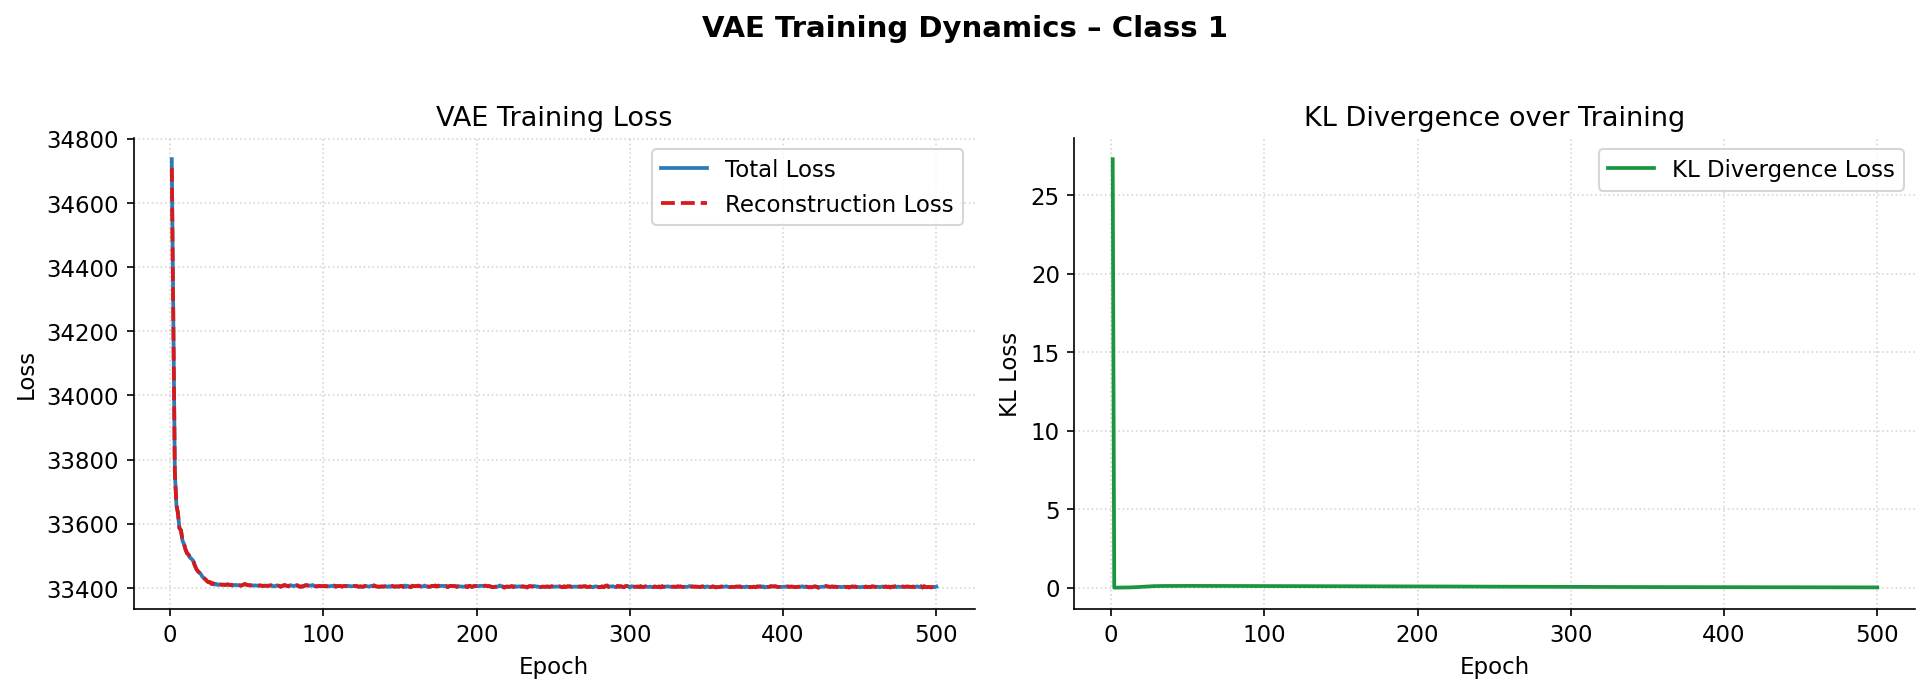

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_vae_training_loss.png


In [ ]:
# --- Step 5: VAE Training Loss Curves (Chapter 5.1) ---
total_loss   = history.history['loss']
recon_loss   = history.history['reconstruction_loss']
kl_loss      = history.history['kl_loss']
epochs_range = range(1, len(total_loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: Total vs. Reconstruction Loss
axes[0].plot(epochs_range, total_loss,  color=COLORS[0], label='Total Loss')
axes[0].plot(epochs_range, recon_loss,  color=COLORS[1], linestyle='--',
             label='Reconstruction Loss')
axes[0].set_title('VAE Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Right: KL Divergence Loss
axes[1].plot(epochs_range, kl_loss, color=COLORS[2], label='KL Divergence Loss')
axes[1].set_title('KL Divergence over Training')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('KL Loss')
axes[1].legend()

plt.suptitle('VAE Training Dynamics – Class 1', fontsize=14,
             fontweight='bold', y=1.02)
plt.tight_layout()
save_path = str(figures_path / 'fig_vae_training_loss.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 6. Generate synthetic Class 1 images

Generate 50 images from standard normal latent samples. WARNING: this section deletes and recreates the existing synthetic-image folder on Google Drive. Do not run it to inspect this archive.


In [ ]:
# WARNING: running this cell replaces the existing synthetic-image folder.
# --- Step 6: Generate and Save Synthetic Images ---
output_dir = dataset_path / 'synthetic_images_class_1'
if output_dir.exists(): shutil.rmtree(output_dir)
output_dir.mkdir(parents=True)

NUM_IMAGES = 50
random_latent_vectors = tf.random.normal(shape=(NUM_IMAGES, latent_dim))
generated_images      = decoder.predict(random_latent_vectors, verbose=0)

for i in range(NUM_IMAGES):
    img_array = (generated_images[i] * 255).astype(np.uint8)
    img       = keras.utils.array_to_img(img_array)
    img.save(output_dir / f"synth_c1_{i:03d}.jpg")

print(f"SUCCESS: {NUM_IMAGES} synthetic images saved to: {output_dir}")


SUCCESS: 50 synthetic images saved to: /content/drive/MyDrive/CarinthiaDataset/synthetic_images_class_1


## 7. Compare original and synthetic images

Display five original images and five generated images for qualitative inspection. This is not a quantitative assessment of generative quality.


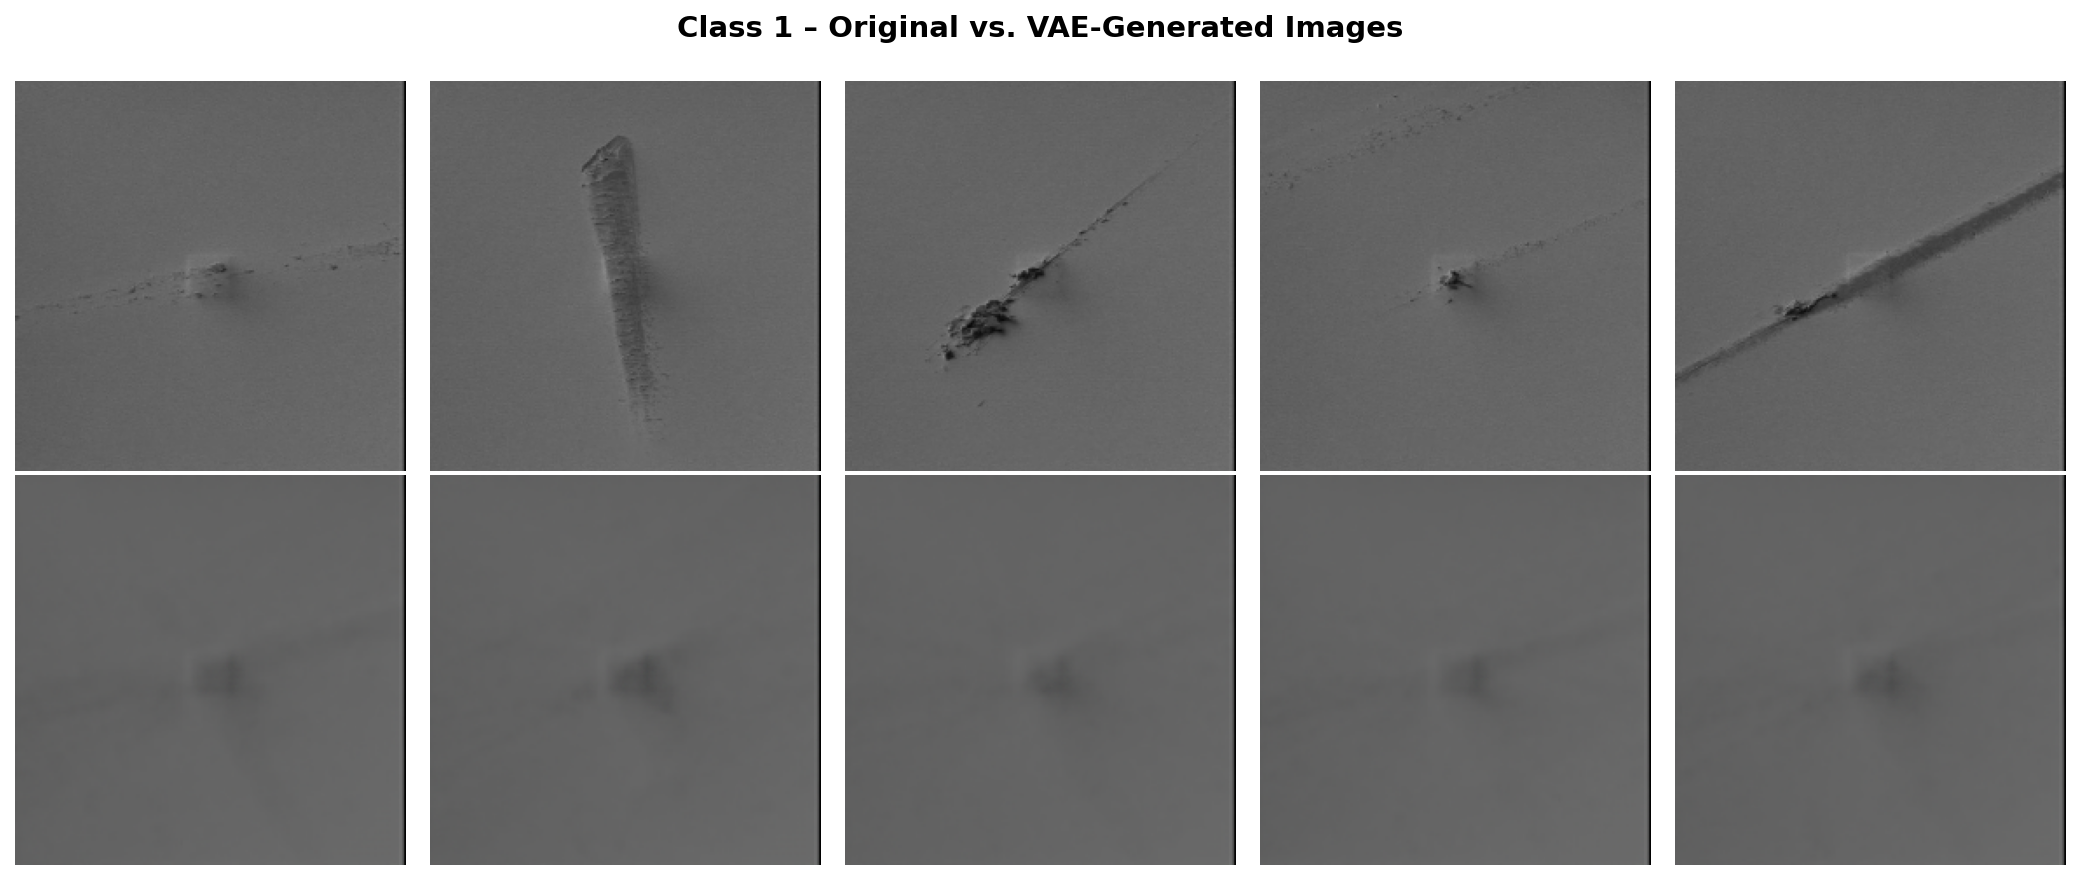

Figure saved: /content/drive/MyDrive/CarinthiaDataset/figures/fig_vae_image_grid.png


In [ ]:
# Compare original and VAE-generated Class 1 images.
n_show = 5  # show 5 originals and 5 synthetic side by side

fig, axes = plt.subplots(2, n_show, figsize=(14, 6))

# Row 1: Original Class 1 images
orig_paths = sorted(local_dir.glob('*.jpg'))[:n_show]
for col, path in enumerate(orig_paths):
    img = tf.image.resize(
        tf.cast(tf.io.decode_jpeg(tf.io.read_file(str(path)), channels=3), tf.float32),
        IMG_SIZE).numpy().astype(np.uint8)
    axes[0, col].imshow(img)
    axes[0, col].axis('off')
    if col == 0:
        axes[0, col].set_ylabel('Original', fontsize=11, fontweight='bold',
                                 labelpad=10)

# Row 2: Synthetic images
for col in range(n_show):
    img_array = (generated_images[col] * 255).astype(np.uint8)
    axes[1, col].imshow(img_array)
    axes[1, col].axis('off')
    if col == 0:
        axes[1, col].set_ylabel('Synthetic\n(VAE)', fontsize=11,
                                 fontweight='bold', labelpad=10)

plt.suptitle('Class 1 – Original vs. VAE-Generated Images',
             fontsize=14, fontweight='bold')
plt.tight_layout()
save_path = str(figures_path / 'fig_vae_image_grid.png')
plt.savefig(save_path, bbox_inches='tight')
plt.show()
print(f"Figure saved: {save_path}")


## 8. Check model interfaces and output range

Check latent and reconstructed shapes and the decoder output range. These checks do not validate generalization, data independence, or image quality.


In [ ]:
# Check encoder/decoder interfaces and output range.
print("=" * 50)
print("  SMOKE TEST & SANITY CHECK – VAE")
print("=" * 50)

# 1. Encoder test
print("\n[1/3] Encoder smoke test...")
dummy = np.random.rand(1, 224, 224, 3).astype(np.float32)
z_mean_out, z_log_var_out, z_out = encoder.predict(dummy, verbose=0)
assert z_out.shape == (1, latent_dim)
print(f"      PASS – Latent vector shape: {z_out.shape}")

# 2. Decoder test
print("\n[2/3] Decoder smoke test...")
dummy_z   = np.random.rand(1, latent_dim).astype(np.float32)
recon_out = decoder.predict(dummy_z, verbose=0)
assert recon_out.shape == (1, 224, 224, 3)
print(f"      PASS – Reconstructed image shape: {recon_out.shape}")

# 3. Pixel range check
print("\n[3/3] Pixel range check (should be 0–1 from sigmoid)...")
assert recon_out.min() >= 0.0 and recon_out.max() <= 1.0
print(f"      PASS – Pixel range: [{recon_out.min():.3f}, {recon_out.max():.3f}]")

print("\n" + "=" * 50)
print("  ALL VAE CHECKS PASSED")
print("=" * 50)


  SMOKE TEST & SANITY CHECK – VAE

[1/3] Encoder smoke test...
      PASS – Latent vector shape: (1, 128)

[2/3] Decoder smoke test...
      PASS – Reconstructed image shape: (1, 224, 224, 3)

[3/3] Pixel range check (should be 0–1 from sigmoid)...
      PASS – Pixel range: [0.004, 0.452]

  ALL VAE CHECKS PASSED
